# Marketing Campaigns — EDA & Hypothesis Testing

**Goal:** understand which factors influence customer acquisition using the 4 Ps of marketing:

| P | Columns |
|---|---------|
| People | `Year_Birth`, `Education`, `Marital_Status`, `Income`, `Kidhome`, `Teenhome` |
| Product | `MntWines`, `MntFruits`, `MntMeatProducts`, `MntFishProducts`, `MntSweetProducts`, `MntGoldProds` |
| Place | `NumWebPurchases`, `NumCatalogPurchases`, `NumStorePurchases`, `NumWebVisitsMonth` |
| Promotion | `NumDealsPurchases`, `AcceptedCmp1-5`, `Response` |

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import OrdinalEncoder

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)

df = pd.read_csv("../1716985255_marketing_campaign_dataset/marketing_data.csv")
print(df.shape)
df.head()

(2240, 28)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,"$84,835.00",0,0,6/16/14,0,189,104,379,111,189,218,1,4,4,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,"$57,091.00",0,0,6/15/14,0,464,5,64,7,0,37,1,7,3,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,"$67,267.00",0,1,5/13/14,0,134,11,59,15,2,30,1,3,2,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,"$32,474.00",1,1,5/11/14,0,10,0,1,0,0,0,1,1,0,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,"$21,474.00",1,0,4/8/14,0,6,16,24,11,0,34,2,3,1,2,7,1,0,0,0,0,1,0,SP


## 1. Check that `Dt_Customer` and `Income` imported correctly
The `Income` header has surrounding spaces and the values are strings such as `"$84,835.00 "`.
`Dt_Customer` is a string in `M/D/YY` format. Both need converting.

In [2]:
df.columns = df.columns.str.strip()
print(df[["Income", "Dt_Customer"]].dtypes)
print(df[["Income", "Dt_Customer"]].head(3))

df["Income"] = (df["Income"].astype(str).str.replace(r"[$,\s]", "", regex=True)
                .replace({"nan": np.nan, "": np.nan}).astype(float))
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%m/%d/%y")

print(df[["Income", "Dt_Customer"]].dtypes)
df[["Income", "Dt_Customer"]].describe()

Income         str
Dt_Customer    str
dtype: object
        Income Dt_Customer
0  $84,835.00      6/16/14
1  $57,091.00      6/15/14
2  $67,267.00      5/13/14
Income                float64
Dt_Customer    datetime64[us]
dtype: object


,Income,Dt_Customer
count,2216.000000,2240
mean,52247.251354,2013-07-10 10:01:42.857142
min,1730.000000,2012-07-30 00:00:00
25%,35303.000000,2013-01-16 00:00:00
50%,51381.500000,2013-07-08 12:00:00
75%,68522.000000,2013-12-30 06:00:00
max,666666.000000,2014-06-29 00:00:00
std,25173.076661,NaN


## 2. Clean categories, then impute missing income by Education × Marital_Status
`Marital_Status` contains invalid labels (`YOLO`, `Absurd`, `Alone`) and `Together` is effectively `Married`.
`Education` has `2n Cycle` (= Master level in the Bologna system) and `Basic`.

In [3]:
print(df["Education"].value_counts(), "\n")
print(df["Marital_Status"].value_counts())

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64 

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
YOLO          2
Absurd        2
Name: count, dtype: int64


In [4]:
df["Marital_Status"] = df["Marital_Status"].replace({
    "Together": "Married", "Alone": "Single", "YOLO": "Single", "Absurd": "Single", "Widow": "Widow"})
df["Education"] = df["Education"].replace({"2n Cycle": "Master"})
print(df["Marital_Status"].value_counts(), "\n")
print(df["Education"].value_counts())

Marital_Status
Married     1444
Single       487
Divorced     232
Widow         77
Name: count, dtype: int64 

Education
Graduation    1127
Master         573
PhD            486
Basic           54
Name: count, dtype: int64


In [5]:
print("Missing income before:", df["Income"].isna().sum())
group_mean = df.groupby(["Education", "Marital_Status"])["Income"].transform("mean")
df["Income"] = df["Income"].fillna(group_mean)
print("Missing income after :", df["Income"].isna().sum())
df.groupby(["Education", "Marital_Status"])["Income"].mean().unstack().round(0)

Missing income before: 24
Missing income after : 0


Marital_Status,Divorced,Married,Single,Widow
Education,,,,
Basic,9548.0,21664.0,18239.0,22123.0
Graduation,54526.0,52779.0,51366.0,54977.0
Master,49973.0,50186.0,53751.0,56211.0
PhD,53097.0,57343.0,53040.0,60288.0


## 3. Feature engineering: children, age, total spending, total purchases
Age is computed relative to 2014 — the last year in which customers enrolled — so it reflects age during the observed period.

In [6]:
mnt_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
purchase_cols = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
REF_YEAR = df["Dt_Customer"].dt.year.max()

df["Total_Children"] = df["Kidhome"] + df["Teenhome"]
df["Age"] = REF_YEAR - df["Year_Birth"]
df["Total_Spending"] = df[mnt_cols].sum(axis=1)
df["Total_Purchases"] = df[purchase_cols].sum(axis=1)
print("Reference year:", REF_YEAR)
df[["Total_Children", "Age", "Total_Spending", "Total_Purchases"]].describe().round(1)

Reference year: 2014


,Total_Children,Age,Total_Spending,Total_Purchases
count,2240.0,2240.0,2240.0,2240.0
mean,1.0,45.2,605.8,12.5
std,0.8,12.0,602.2,7.2
min,0.0,18.0,5.0,0.0
25%,0.0,37.0,68.8,6.0
50%,1.0,44.0,396.0,12.0
75%,1.0,55.0,1045.5,18.0
max,3.0,121.0,2525.0,32.0


## 4. Distributions & outliers (box plots + histograms)

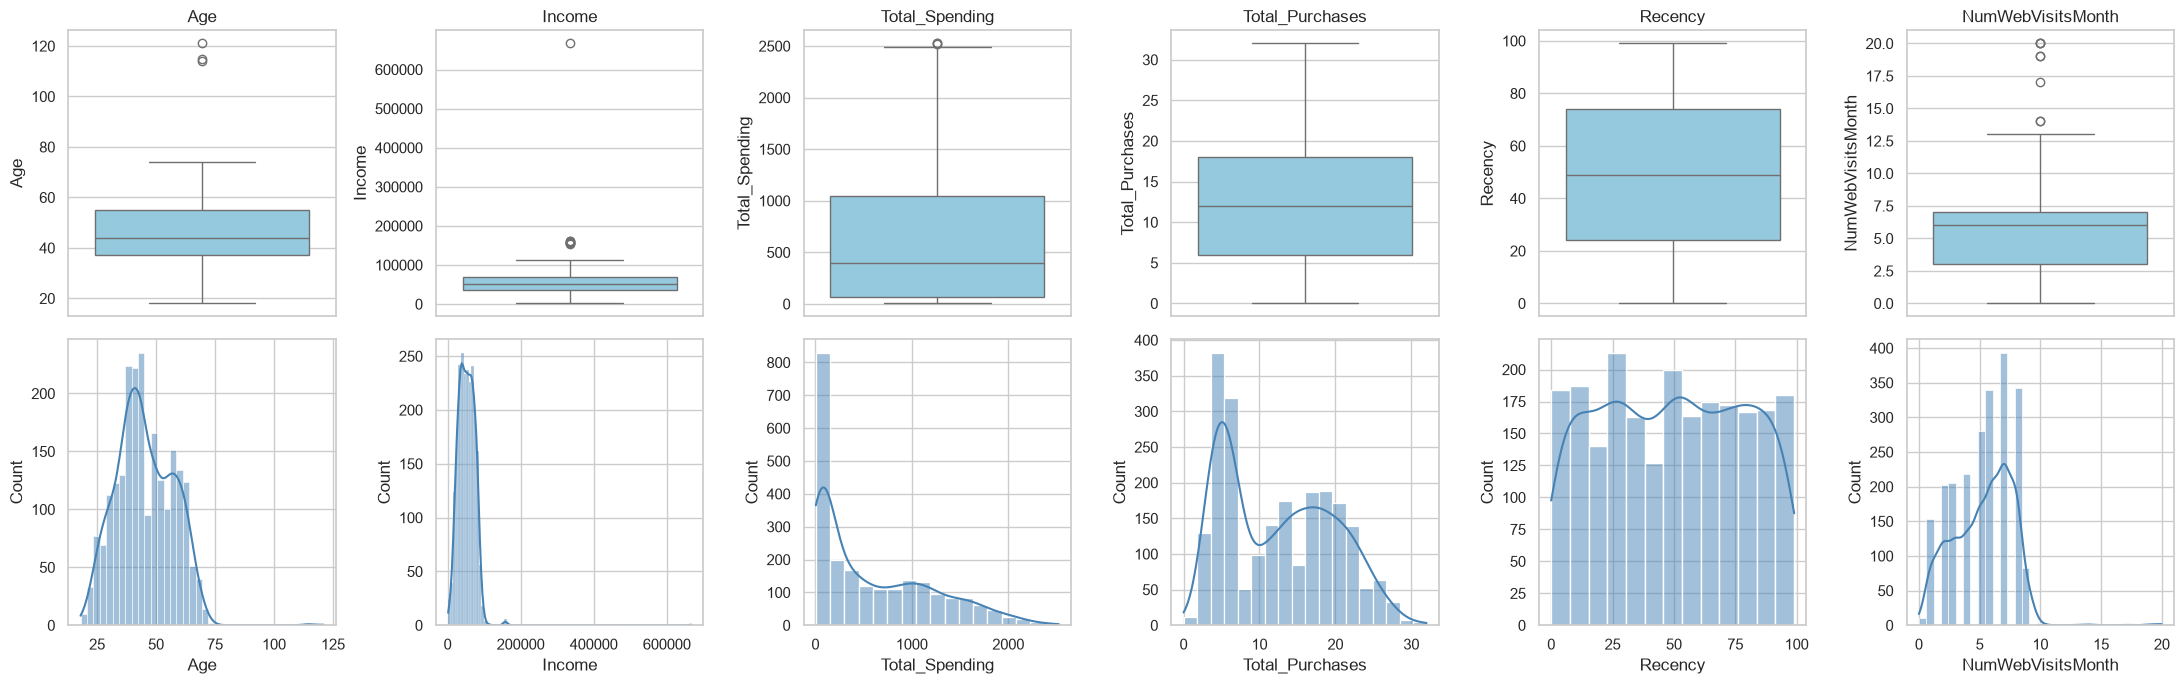

In [7]:
num_cols = ["Age", "Income", "Total_Spending", "Total_Purchases", "Recency", "NumWebVisitsMonth"]
fig, axes = plt.subplots(2, len(num_cols), figsize=(22, 7))
for i, c in enumerate(num_cols):
    sns.boxplot(y=df[c], ax=axes[0, i], color="skyblue")
    sns.histplot(df[c], kde=True, ax=axes[1, i], color="steelblue")
    axes[0, i].set_title(c)
plt.tight_layout(); plt.show()

**Outliers found:** `Age` has three customers born before 1901 (age > 110 — data-entry errors) and `Income` has one extreme value (666,666) far above the rest.
These are impossible/implausible, so they are removed. Spending and purchases are naturally right-skewed but valid, so they are kept.

Age: extreme outliers outside [-17, 109] -> [121, 115, 114]
Income: extreme outliers outside [-62714, 166543] -> [666666.0]
Removed 4 rows; remaining 2236


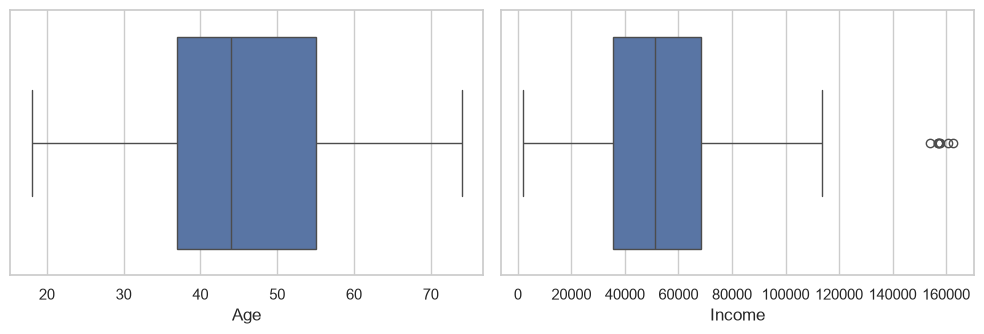

In [8]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

for c in ["Age", "Income"]:
    lo, hi = iqr_bounds(df[c], k=3)
    print(f"{c}: extreme outliers outside [{lo:.0f}, {hi:.0f}] ->", df.loc[(df[c] < lo) | (df[c] > hi), c].tolist())

before = len(df)
df = df[(df["Age"] < 100) & (df["Income"] < 200_000)].copy()
print(f"Removed {before - len(df)} rows; remaining {len(df)}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.boxplot(x=df["Age"], ax=axes[0]); sns.boxplot(x=df["Income"], ax=axes[1])
plt.tight_layout(); plt.show()

## 5. Encoding
* **Ordinal:** `Education` has a natural order → Basic < Graduation < Master < PhD.
* **One-hot:** `Marital_Status` and `Country` are nominal.

In [9]:
edu_order = [["Basic", "Graduation", "Master", "PhD"]]
df["Education_Ord"] = OrdinalEncoder(categories=edu_order).fit_transform(df[["Education"]]).ravel()
df_enc = pd.get_dummies(df, columns=["Marital_Status", "Country"], prefix=["MS", "C"], dtype=int)
print(df_enc.filter(regex="^(Education|MS_|C_)").head())
print("Encoded shape:", df_enc.shape)

    Education  Education_Ord  MS_Divorced  MS_Married  MS_Single  MS_Widow  \
0  Graduation            1.0            1           0          0         0   
1  Graduation            1.0            0           0          1         0   
2  Graduation            1.0            0           1          0         0   
3  Graduation            1.0            0           1          0         0   
4  Graduation            1.0            0           0          1         0   

   C_AUS  C_CA  C_GER  C_IND  C_ME  C_SA  C_SP  C_US  
0      0     0      0      0     0     0     1     0  
1      0     1      0      0     0     0     0     0  
2      0     0      0      0     0     0     0     1  
3      1     0      0      0     0     0     0     0  
4      0     0      0      0     0     0     1     0  
Encoded shape: (2236, 43)


## 6. Correlation heatmap

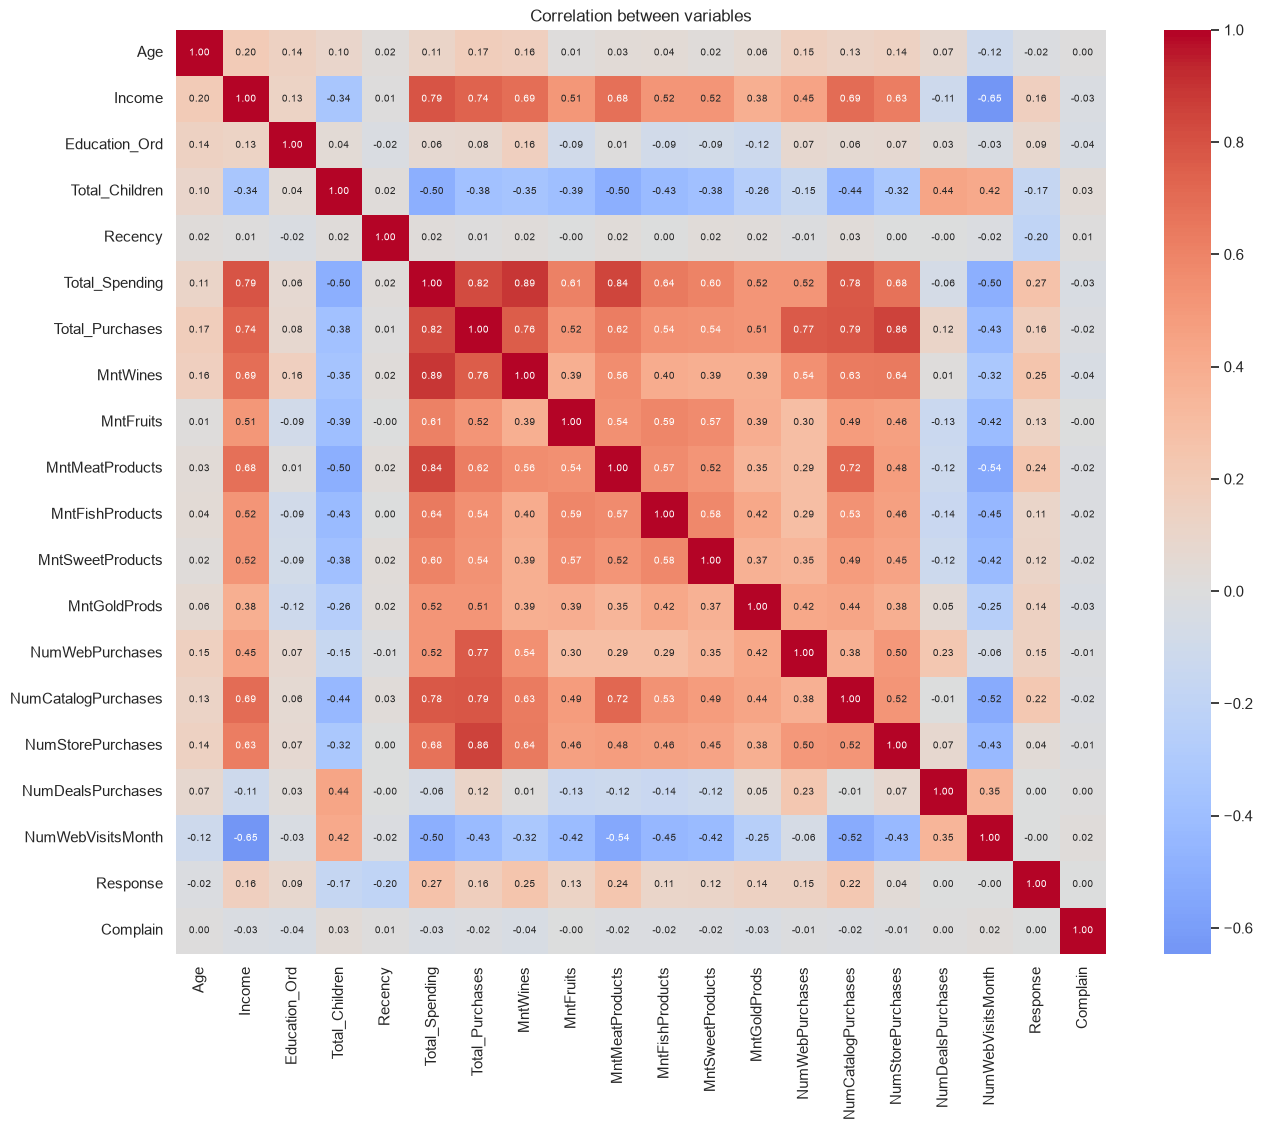

In [10]:
corr_cols = (["Age", "Income", "Education_Ord", "Total_Children", "Recency", "Total_Spending", "Total_Purchases"]
             + mnt_cols + purchase_cols + ["NumDealsPurchases", "NumWebVisitsMonth", "Response", "Complain"])
plt.figure(figsize=(15, 12))
sns.heatmap(df_enc[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation between variables"); plt.show()

**Observations:** Income is strongly positively correlated with total spending (≈0.8), wine/meat spending and catalog/store purchases,
and negatively with web visits. Number of children is negatively correlated with spending and positively with deal purchases.
The last-campaign `Response` correlates most with spending, catalog purchases and income.

## 7. Hypothesis tests (α = 0.05)
Non-parametric tests are used because the purchase counts are skewed and not normally distributed.

In [11]:
ALPHA = 0.05
def verdict(p): return "REJECT H0" if p < ALPHA else "fail to reject H0"
df["Store_Share"] = df["NumStorePurchases"] / df["Total_Purchases"].replace(0, np.nan)
df["Web_Share"] = df["NumWebPurchases"] / df["Total_Purchases"].replace(0, np.nan)

### 7a. Older customers prefer in-store shopping
H0: share of store purchases does not increase with age. H1: older customers have a higher store share.

In [12]:
rho, p_rho = stats.spearmanr(df["Age"], df["Store_Share"], nan_policy="omit")
older = df.loc[df["Age"] >= 55, "Store_Share"].dropna()
younger = df.loc[df["Age"] < 55, "Store_Share"].dropna()
u, p_u = stats.mannwhitneyu(older, younger, alternative="greater")
print(f"Spearman rho(age, store share) = {rho:.3f}, p = {p_rho:.4f}")
print(f"Median store share: 55+ = {older.median():.3f}, <55 = {younger.median():.3f}")
print(f"Mann-Whitney (55+ > <55) p = {p_u:.4f} -> {verdict(p_u)}")

Spearman rho(age, store share) = -0.114, p = 0.0000
Median store share: 55+ = 0.476, <55 = 0.500
Mann-Whitney (55+ > <55) p = 1.0000 -> fail to reject H0


**Result:** not supported. Store share actually *decreases* slightly with age (ρ ≈ −0.11) and customers aged 55+ do not have a higher store share.
Older customers (who also have higher incomes) shift purchases toward the **catalog** channel, not the store.

### 7b. Customers with children prefer online shopping
H0: web-purchase share is the same for customers with and without children. H1: higher for customers with children.

In [13]:
with_kids = df.loc[df["Total_Children"] > 0, "Web_Share"].dropna()
no_kids = df.loc[df["Total_Children"] == 0, "Web_Share"].dropna()
u, p_b = stats.mannwhitneyu(with_kids, no_kids, alternative="greater")
print(f"Median web share: with children = {with_kids.median():.3f}, without = {no_kids.median():.3f}")
print(f"Mann-Whitney p = {p_b:.4g} -> {verdict(p_b)}")
print("Mean absolute web purchases: with kids = %.2f, without = %.2f" %
      (df.loc[df.Total_Children > 0, "NumWebPurchases"].mean(), df.loc[df.Total_Children == 0, "NumWebPurchases"].mean()))

Median web share: with children = 0.333, without = 0.263
Mann-Whitney p = 1.193e-52 -> REJECT H0
Mean absolute web purchases: with kids = 3.97, without = 4.39


**Result:** supported. Customers with children make a significantly larger *share* of their purchases online (median 33% vs 26%, p < 0.001),
even though they buy slightly fewer items overall. Online convenience matters to parents.

### 7c. Store sales cannibalised by other channels
If other channels cannibalise store sales, store purchases should be **negatively** correlated with web/catalog purchases.
H0: no negative correlation.

In [14]:
for ch in ["NumWebPurchases", "NumCatalogPurchases"]:
    r, p = stats.spearmanr(df["NumStorePurchases"], df[ch])
    p_one = p / 2 if r < 0 else 1 - p / 2
    print(f"Store vs {ch}: rho = {r:.3f}, one-sided p(negative) = {p_one:.4f} -> {verdict(p_one)}")
r, p = stats.spearmanr(df["NumStorePurchases"], df["NumWebVisitsMonth"])
print(f"Store purchases vs web visits: rho = {r:.3f}, p = {p:.4f}")

Store vs NumWebPurchases: rho = 0.672, one-sided p(negative) = 1.0000 -> fail to reject H0
Store vs NumCatalogPurchases: rho = 0.709, one-sided p(negative) = 1.0000 -> fail to reject H0
Store purchases vs web visits: rho = -0.456, p = 0.0000


**Result:** no evidence that web or catalog *purchases* cannibalise store purchases — they rise together (ρ ≈ 0.67 and 0.71):
customers who buy more, buy more everywhere. **However**, customers who *visit the website often* make fewer store purchases (ρ ≈ −0.46).
These frequent visitors are typically lower-income parents browsing for deals, so the risk to stores is from browsing/deal-seeking behaviour, not from web sales.

### 7d. Does the US significantly outperform the rest of the world in total purchases?
H0: US total purchases ≤ rest of the world. H1: US > rest of world.

In [15]:
us = df.loc[df["Country"] == "US", "Total_Purchases"]
row = df.loc[df["Country"] != "US", "Total_Purchases"]
u, p_d = stats.mannwhitneyu(us, row, alternative="greater")
t, p_t = stats.ttest_ind(us, row, equal_var=False, alternative="greater")
print(f"Mean total purchases: US = {us.mean():.2f} (n={len(us)}), rest = {row.mean():.2f} (n={len(row)})")
print(f"Mann-Whitney p = {p_d:.4f}, Welch t-test p = {p_t:.4f} -> {verdict(p_d)}")
print("\nTotal purchase volume by country (sum):")
print(df.groupby("Country")["Total_Purchases"].agg(["sum", "mean", "count"]).sort_values("sum", ascending=False).round(2))

Mean total purchases: US = 13.51 (n=109), rest = 12.50 (n=2127)
Mann-Whitney p = 0.0730, Welch t-test p = 0.0743 -> fail to reject H0

Total purchase volume by country (sum):
           sum   mean  count
Country                     
SP       13569  12.40   1094
SA        4292  12.81    335
CA        3457  12.90    268
AUS       1952  12.20    160
IND       1729  11.76    147
GER       1530  12.75    120
US        1473  13.51    109
ME          52  17.33      3


**Result:** not significant at α = 0.05 (p ≈ 0.07). US customers buy slightly more per person (13.5 vs 12.5), but in total volume the US
ranks only 7th of 8 because of its small customer base; Spain (SP) dominates total volume.

## 8. Visual analysis
### 8a. Top-performing and lowest-revenue products

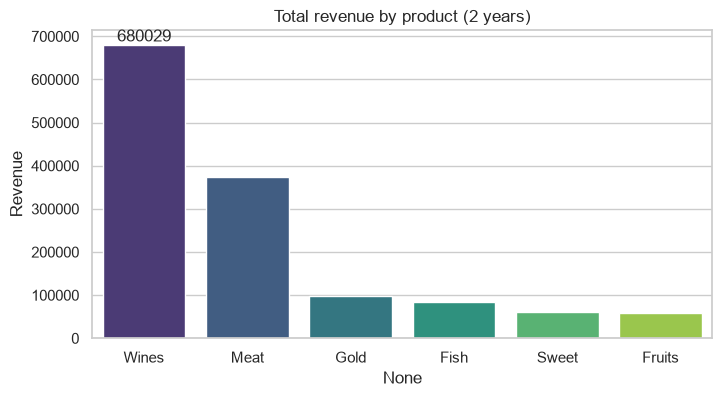

Wines     680029
Meat      373375
Gold       98346
Fish       83931
Sweet      60552
Fruits     58753
dtype: int64


In [16]:
product_rev = df[mnt_cols].sum().sort_values(ascending=False)
product_rev.index = product_rev.index.str.replace("Mnt", "").str.replace("Products", "").str.replace("Prods", "")
plt.figure(figsize=(8, 4))
ax = sns.barplot(x=product_rev.index, y=product_rev.values, palette="viridis")
ax.bar_label(ax.containers[0], fmt="%.0f"); plt.title("Total revenue by product (2 years)"); plt.ylabel("Revenue")
plt.show()
print(product_rev)

**Wine** is the top revenue product by far (~680k), followed by **meat** (~373k). **Fruits** and **sweets** generate the least revenue.

### 8b. Age vs. acceptance of the last campaign

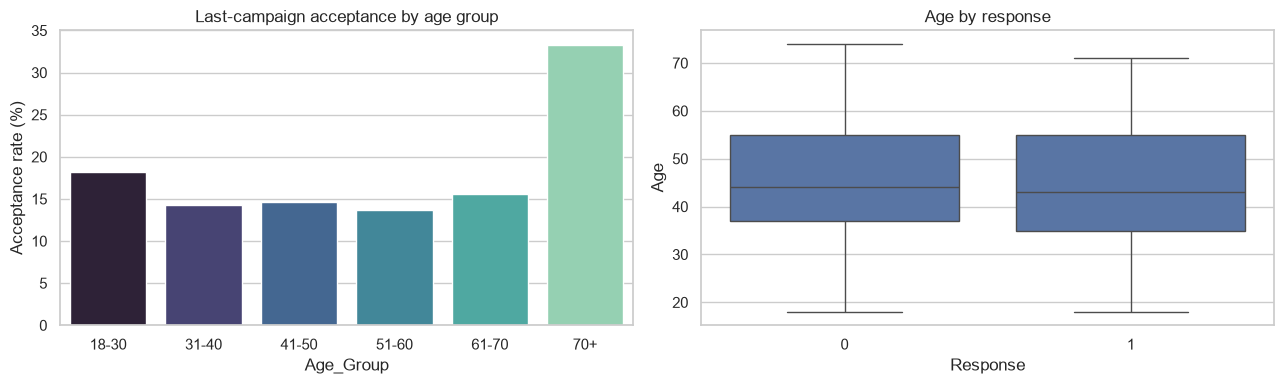

Point-biserial correlation age vs response: r = -0.019, p = 0.380


In [17]:
df["Age_Group"] = pd.cut(df["Age"], bins=[17, 30, 40, 50, 60, 70, 100], labels=["18-30", "31-40", "41-50", "51-60", "61-70", "70+"])
acc = df.groupby("Age_Group", observed=True)["Response"].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(x=acc.index, y=acc.values, ax=axes[0], palette="mako"); axes[0].set_ylabel("Acceptance rate (%)")
axes[0].set_title("Last-campaign acceptance by age group")
sns.boxplot(x="Response", y="Age", data=df, ax=axes[1]); axes[1].set_title("Age by response")
plt.tight_layout(); plt.show()
r_pb, p_pb = stats.pointbiserialr(df["Response"], df["Age"])
print(f"Point-biserial correlation age vs response: r = {r_pb:.3f}, p = {p_pb:.3f}")

There is **no meaningful correlation** between age and accepting the last campaign (r ≈ −0.02, p ≈ 0.38). The youngest group (18-30) has a slightly higher rate.

### 8c. Country with the most customers who accepted the last campaign

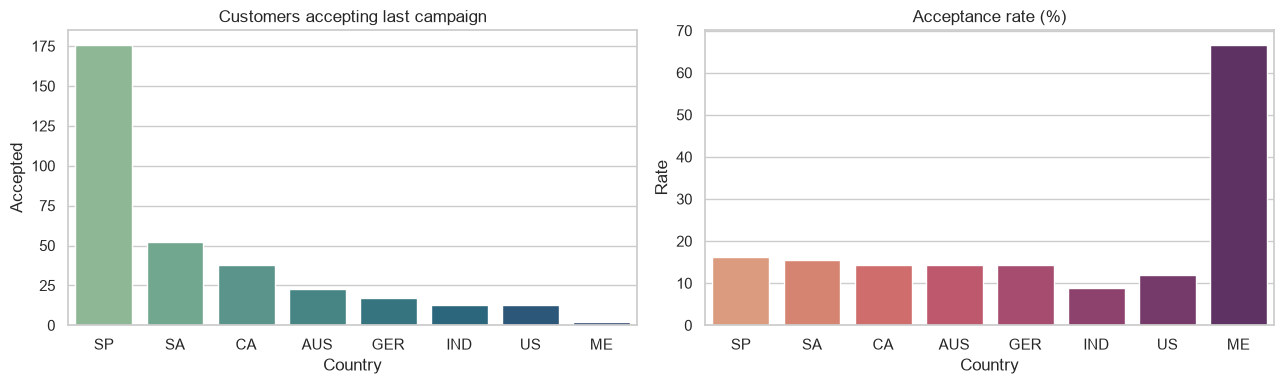

,Accepted,Rate
Country,,
SP,176,16.1
SA,52,15.5
CA,38,14.2
AUS,23,14.4
GER,17,14.2
IND,13,8.8
US,13,11.9
ME,2,66.7


In [18]:
by_country = df.groupby("Country")["Response"].agg(Accepted="sum", Rate="mean").sort_values("Accepted", ascending=False)
by_country["Rate"] = (by_country["Rate"] * 100).round(1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(x=by_country.index, y=by_country["Accepted"], ax=axes[0], palette="crest"); axes[0].set_title("Customers accepting last campaign")
sns.barplot(x=by_country.index, y=by_country["Rate"], ax=axes[1], palette="flare"); axes[1].set_title("Acceptance rate (%)")
plt.tight_layout(); plt.show()
by_country

by_country

**Spain (SP)** has by far the most customers accepting the last campaign (176). ME has a 67% rate but only 3 customers, so it is not meaningful.

### 8d. Children at home vs. total expenditure

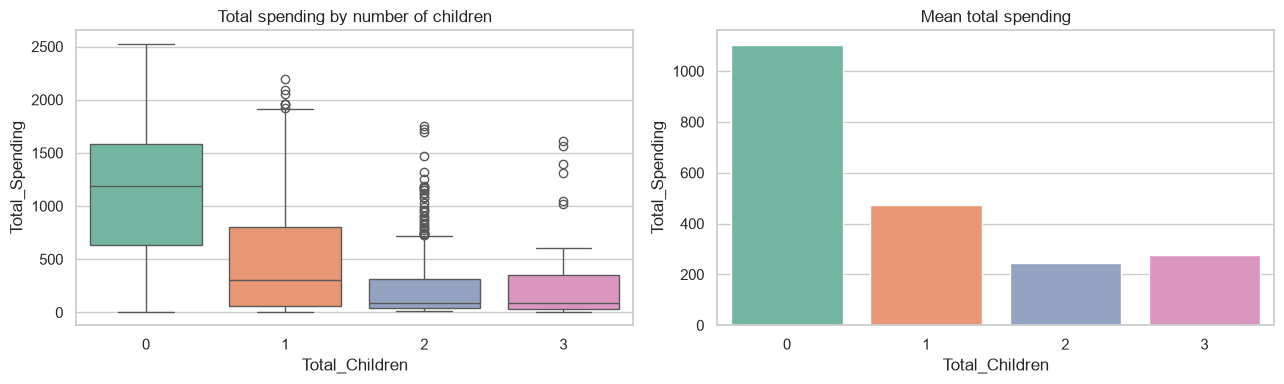

,mean,median,count
Total_Children,,,
0,1105.0,1189.0,637
1,474.0,306.0,1125
2,246.0,93.0,421
3,275.0,88.0,53


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(x="Total_Children", y="Total_Spending", data=df, ax=axes[0], palette="Set2"); axes[0].set_title("Total spending by number of children")
sns.barplot(x="Total_Children", y="Total_Spending", data=df, ax=axes[1], palette="Set2", errorbar=None); axes[1].set_title("Mean total spending")
plt.tight_layout(); plt.show()
df.groupby("Total_Children")["Total_Spending"].agg(["mean", "median", "count"]).round(0)
df.groupby("Total_Children")["Total_Spending"].agg(["mean", "median", "count"]).round(0)

Clear pattern: customers **without children spend ~2-4× more** than those with children (mean 1,105 vs 474 for one child and ~250 for 2-3 children).

### 8e. Education of customers who complained in the last two years

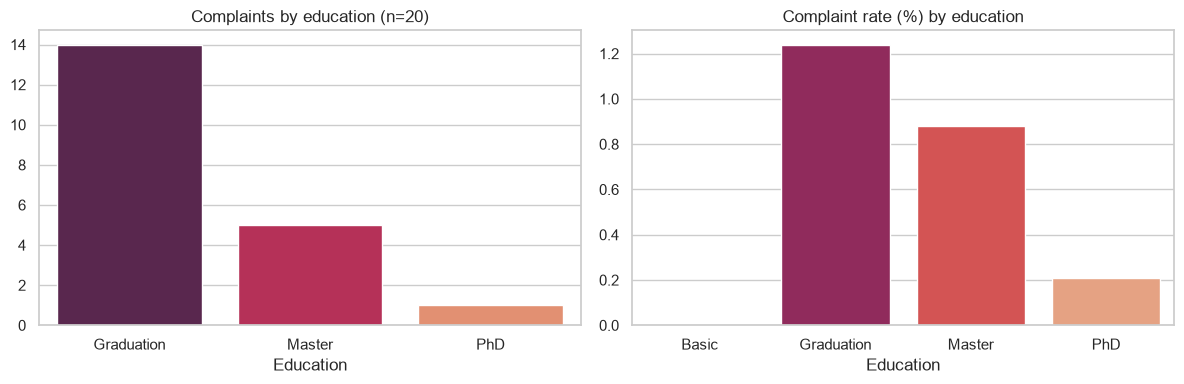

,complaints,rate_%
Education,,
Basic,0,0.00
Graduation,14,1.24
Master,5,0.88
PhD,1,0.21


In [20]:
comp = df[df["Complain"] == 1]
edu_counts = comp["Education"].value_counts()
edu_rate = (df.groupby("Education")["Complain"].mean() * 100).round(2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=edu_counts.index, y=edu_counts.values, ax=axes[0], palette="rocket"); axes[0].set_title(f"Complaints by education (n={len(comp)})")
sns.barplot(x=edu_rate.index, y=edu_rate.values, ax=axes[1], palette="rocket"); axes[1].set_title("Complaint rate (%) by education")
plt.tight_layout(); plt.show()
pd.DataFrame({"complaints": edu_counts, "rate_%": edu_rate}).fillna(0).astype({"complaints": int})

Most complaints come from **Graduation**-level customers (14 of 20), which is also the largest group; their complaint rate (1.2%) is the highest. PhD holders complain least.

## Summary & recommendations
* **People:** income drives spending; households with children spend much less but shop online proportionally more → target parents with web offers and convenience (delivery, bundles).
* **Product:** wine and meat bring most revenue → keep them central to campaigns; fruits/sweets are good for cross-selling.
* **Place:** channels complement each other — no store cannibalisation — so an omnichannel strategy is safe, but watch heavy web-browsers who buy less in store. Older, wealthier customers lean on catalogs.
* **Promotion:** campaign response is not driven by age; Spain is the strongest market in absolute acceptances. The US does not significantly outperform other countries.